# Step 9 — Which way round the circle, and how often?

**Step 8 found that a trained run settles on one of two mirror-image policies.** Under ranked
seating, always shooting left is `next_weaker`: each player fires at the next weaker one and the
weakest at the strongest. Always shooting right is its mirror, `next_stronger`: each player fires
at the next stronger one and the strongest at the weakest. Four of step 8's twenty runs at 10 and
15 players fired right. Steps 1 to 7 used seeds 0 to 2, which all fire left, so every result
this folder reports past the answer key rests on the left-shooting policy without saying how
common it is.

**This step measures how common each direction is, and what the difference does.** The agent is
step 1's, MAPPO with the centralised critic, trained on twenty seeds at 7, 10 and 15 players.
Seven is included because there the exact answer is known, so each direction can be checked
against it.

**This notebook trains nothing.** `train_and_measure.py` trains and measures all sixty runs in
parallel and writes one result file and one saved model per run, as in step 8.

In [1]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import torch

from gruel_env import GruelEnv, MISS, SHOOT_LEFT, SHOOT_RIGHT
import train_and_measure as script

PLAYER_COUNTS = script.PLAYER_COUNTS
SEEDS = script.SEEDS
ARM = "centralised"
SEED = 0

print("player counts:", PLAYER_COUNTS, " seeds:", len(SEEDS), "(%d to %d)" % (SEEDS[0], SEEDS[-1]))
print("budget per run:", script.UPDATES, "updates x", script.EPISODES_PER_UPDATE, "episodes")
print("measured episodes per run:", script.EVALUATION_EPISODES)

player counts: [7, 10, 15]  seeds: 20 (0 to 19)
budget per run: 2000 updates x 96 episodes
measured episodes per run: 10000


## The result files

In [2]:
R = {}
missing = []
for n in PLAYER_COUNTS:
    for seed in SEEDS:
        path = script.result_path(n, ARM, seed)
        if not os.path.exists(path):
            missing.append(os.path.basename(path))
            continue
        with open(path) as handle:
            R[(n, seed)] = json.load(handle)
if missing:
    raise FileNotFoundError("run train_and_measure.py first; missing: " + ", ".join(missing))

print("result files read:", len(R))
for n in PLAYER_COUNTS:
    minutes = [R[(n, seed)]["total_minutes"] for seed in SEEDS]
    print("  N=%-3d minutes per run, %.1f to %.1f" % (n, min(minutes), max(minutes)))
stalled = 0
for key in R:
    if R[key]["stagnation_rate"] >= 0.01 or R[key]["hard_cap_rate"] >= 0.01:
        stalled = stalled + 1
print("runs stalling or hitting the cap in 1% or more of episodes:", stalled)

result files read: 60
  N=7   minutes per run, 6.0 to 10.2
  N=10  minutes per run, 15.7 to 17.1
  N=15  minutes per run, 29.2 to 34.9
runs stalling or hitting the cap in 1% or more of episodes: 0


## The two directions, and how a run is classified

With $k$ players alive and ranked seating, shooting left hits the stronger neighbour at 2 of the
$k$ seats and shooting right at $k-2$. So the share of shots at the stronger neighbour with the
**whole field alive** is near $2/N$ for a left-shooter and near $(N-2)/N$ for a right-shooter. A
run is classified by whichever it is nearer. A run more than 0.10 from both is also flagged as
**mixed**, because a run that fires partly each way is a third outcome and should not be hidden
inside one of the other two.

In [3]:
MIXED_MARGIN = 0.10
SHARE = {}
DIRECTION = {}
MIXED = {}
for n in PLAYER_COUNTS:
    left_value = 2.0 / n
    right_value = (n - 2.0) / n
    print("  N=%d   left gives %.4f, right gives %.4f" % (n, left_value, right_value))
    cells = []
    for seed in SEEDS:
        share = R[(n, seed)]["targeting_by_alive"][str(n)]
        SHARE[(n, seed)] = share
        if abs(share - left_value) <= abs(share - right_value):
            DIRECTION[(n, seed)] = "left"
        else:
            DIRECTION[(n, seed)] = "right"
        MIXED[(n, seed)] = min(abs(share - left_value), abs(share - right_value)) > MIXED_MARGIN
        mark = DIRECTION[(n, seed)] + ("*" if MIXED[(n, seed)] else "")
        cells.append("%2d %.4f %-6s" % (seed, share, mark))
    for row in range(0, len(cells), 5):
        print("    " + "   ".join(cells[row:row + 5]))
    print()
print("  * more than %.2f from both values: mixed" % MIXED_MARGIN)

  N=7   left gives 0.2857, right gives 0.7143
     0 0.2834 left      1 0.2810 left      2 0.2823 left      3 0.2857 left      4 0.2836 left  
     5 0.2887 left      6 0.7098 right     7 0.2849 left      8 0.2869 left      9 0.2860 left  
    10 0.2926 left     11 0.2834 left     12 0.2837 left     13 0.2833 left     14 0.2846 left  
    15 0.2876 left     16 0.2890 left     17 0.7147 right    18 0.2872 left     19 0.2880 left  

  N=10   left gives 0.2000, right gives 0.8000
     0 0.1947 left      1 0.2013 left      2 0.1973 left      3 0.8034 right     4 0.8039 right 
     5 0.1937 left      6 0.2072 left      7 0.1986 left      8 0.1979 left      9 0.2045 left  
    10 0.1984 left     11 0.1975 left     12 0.2008 left     13 0.2040 left     14 0.1924 left  
    15 0.2015 left     16 0.1991 left     17 0.1981 left     18 0.2015 left     19 0.2025 left  

  N=15   left gives 0.1333, right gives 0.8667
     0 0.1304 left      1 0.1191 left      2 0.1380 left      3 0.1358 left      4

## Check: seeds 0 to 4 are steps 1 and 8

Seeds 0 to 4 at 10 and 15 players are the centralised runs of step 8, trained and measured the
same way, so their full-field shares are quoted from step 8's output and must reproduce. At
seven players seeds 0 to 4 are deliverable 03 step 10's centralised runs, which all fire left.

In [4]:
STEP8_SHARES = {
    10: [0.1947, 0.2013, 0.1973, 0.8034, 0.8039],
    15: [0.1304, 0.1191, 0.1380, 0.1358, 0.9321],
}
reproduces = True
for n in STEP8_SHARES:
    here = [round(SHARE[(n, seed)], 4) for seed in range(5)]
    same = here == STEP8_SHARES[n]
    if not same:
        reproduces = False
    print("  N=%-3d step 8 %s   here %s   %s" % (n, STEP8_SHARES[n], here, "same" if same else "DIFFERENT"))
seven_left = [DIRECTION[(7, seed)] for seed in range(5)]
print("  N=7   deliverable 03 step 10: all five left   here %s" % seven_left)
print()
print("reproduces step 8:", reproduces, "  N=7 seeds 0 to 4 all left:", seven_left == ["left"] * 5)

  N=10  step 8 [0.1947, 0.2013, 0.1973, 0.8034, 0.8039]   here [0.1947, 0.2013, 0.1973, 0.8034, 0.8039]   same
  N=15  step 8 [0.1304, 0.1191, 0.138, 0.1358, 0.9321]   here [0.1304, 0.1191, 0.138, 0.1358, 0.9321]   same
  N=7   deliverable 03 step 10: all five left   here ['left', 'left', 'left', 'left', 'left']

reproduces step 8: True   N=7 seeds 0 to 4 all left: True


## How often each direction is learned

The rate of right-shooting runs at each player count, with the exact binomial (Clopper-Pearson)
95% interval, computed by bisection as in step 7.

In [5]:
def binomial_tail_at_least(k, n, p):
    """P(X >= k) for X ~ Binomial(n, p)."""
    total = 0.0
    for count in range(k, n + 1):
        ways = 1
        for i in range(count):
            ways = ways * (n - i) // (i + 1)
        total = total + ways * (p ** count) * ((1 - p) ** (n - count))
    return total


def binomial_tail_at_most(k, n, p):
    """P(X <= k) for X ~ Binomial(n, p)."""
    return 1.0 - binomial_tail_at_least(k + 1, n, p)


def bisect(condition, low, high):
    """The point in [low, high] where condition switches from False to True."""
    for _ in range(100):
        middle = (low + high) / 2
        if condition(middle):
            high = middle
        else:
            low = middle
    return (low + high) / 2


def exact_interval(k, n):
    if k == 0:
        lower = 0.0
    else:
        lower = bisect(lambda p: binomial_tail_at_least(k, n, p) >= 0.025, 0.0, 1.0)
    if k == n:
        upper = 1.0
    else:
        upper = bisect(lambda p: binomial_tail_at_most(k, n, p) <= 0.025, 0.0, 1.0)
    return lower, upper


RIGHT_COUNT = {}
for n in PLAYER_COUNTS:
    rights = [seed for seed in SEEDS if DIRECTION[(n, seed)] == "right"]
    mixed = [seed for seed in SEEDS if MIXED[(n, seed)]]
    RIGHT_COUNT[n] = len(rights)
    lower, upper = exact_interval(len(rights), len(SEEDS))
    print("  N=%-3d right in %2d of %d, rate %.2f, 95%% interval %.4f to %.4f;  right seeds %s;  mixed %s"
          % (n, len(rights), len(SEEDS), len(rights) / len(SEEDS), lower, upper, rights, mixed))

total_right = sum(RIGHT_COUNT.values())
total_runs = len(SEEDS) * len(PLAYER_COUNTS)
lower, upper = exact_interval(total_right, total_runs)
print()
print("  all three counts: right in %d of %d, rate %.2f, 95%% interval %.4f to %.4f"
      % (total_right, total_runs, total_right / total_runs, lower, upper))

  N=7   right in  2 of 20, rate 0.10, 95% interval 0.0123 to 0.3170;  right seeds [6, 17];  mixed []
  N=10  right in  2 of 20, rate 0.10, 95% interval 0.0123 to 0.3170;  right seeds [3, 4];  mixed []
  N=15  right in  4 of 20, rate 0.20, 95% interval 0.0573 to 0.4366;  right seeds [4, 8, 18, 19];  mixed [13]

  all three counts: right in 8 of 60, rate 0.13, 95% interval 0.0594 to 0.2459


**Does the rate depend on the player count?** A permutation test: if the player count made no
difference, the sixty runs' directions could be shuffled among the three counts freely. The test
counts how often a shuffle gives a spread of counts at least as large as the one observed. Its
random stream is its own, seeded.

In [6]:
def spread(counts):
    return max(counts) - min(counts)


observed = spread([RIGHT_COUNT[n] for n in PLAYER_COUNTS])
labels = []
for n in PLAYER_COUNTS:
    for seed in SEEDS:
        labels.append(1 if DIRECTION[(n, seed)] == "right" else 0)
permutation_rng = np.random.default_rng(SEED)
PERMUTATIONS = 20000
as_large = 0
for _ in range(PERMUTATIONS):
    shuffled = permutation_rng.permutation(labels)
    counts = []
    for index in range(len(PLAYER_COUNTS)):
        counts.append(int(shuffled[index * len(SEEDS):(index + 1) * len(SEEDS)].sum()))
    if spread(counts) >= observed:
        as_large = as_large + 1
p_value = as_large / PERMUTATIONS
print("  observed spread of right counts across N: %d" % observed)
print("  share of %d shuffles with a spread at least as large: %.4f" % (PERMUTATIONS, p_value))
if p_value < 0.05:
    print("  -> the rate differs measurably with the player count")
else:
    print("  -> no measurable dependence on the player count")

  observed spread of right counts across N: 2
  share of 20000 shuffles with a spread at least as large: 0.7071
  -> no measurable dependence on the player count


## The two references, measured

`next_weaker` always shoots left under ranked seating; `next_stronger`, its mirror, always shoots
right. Each is played in the same game, so each run's targeting can be read against the rule its
direction belongs to.

In [7]:
def next_weaker(game, actor):
    """Archetti's rule on the circle: the strongest neighbour still weaker than you, else the stronger."""
    left, right = game.neighbours(actor)
    mine = game.accuracies[actor]
    pool = []
    for candidate in (left, right):
        if game.accuracies[candidate] < mine:
            pool.append(candidate)
    if len(pool) == 0:
        pool = [left, right]      # both outgun you: you are the weak one, so fire at the stronger
    target = pool[0]
    for candidate in pool:
        if game.accuracies[candidate] > game.accuracies[target]:
            target = candidate
    if target == left:
        return SHOOT_LEFT
    return SHOOT_RIGHT


def next_stronger(game, actor):
    """The mirror rule: the weakest neighbour still stronger than you, else the weaker."""
    left, right = game.neighbours(actor)
    mine = game.accuracies[actor]
    pool = []
    for candidate in (left, right):
        if game.accuracies[candidate] > mine:
            pool.append(candidate)
    if len(pool) == 0:
        pool = [left, right]      # nobody outguns you: you are the strongest, so fire at the weaker
    target = pool[0]
    for candidate in pool:
        if game.accuracies[candidate] < game.accuracies[target]:
            target = candidate
    if target == left:
        return SHOOT_LEFT
    return SHOOT_RIGHT


RULE = {}
for n in PLAYER_COUNTS:
    for name, rule in [("next_weaker", next_weaker), ("next_stronger", next_stronger)]:
        game = GruelEnv(n=n, reward=script.REWARD, seating=script.SEATING, seed=7000 + n)
        records = script.play_episodes(game, rule, 10000)
        RULE[(n, name)] = script.summarise(records, n)
    print("  N=%-3d full-field share: next_weaker %.4f, next_stronger %.4f;  weakest x even share: %.3f, %.3f"
          % (n, RULE[(n, "next_weaker")]["targeting_by_alive"][str(n)],
             RULE[(n, "next_stronger")]["targeting_by_alive"][str(n)],
             RULE[(n, "next_weaker")]["survival_by_rank"][0] * n,
             RULE[(n, "next_stronger")]["survival_by_rank"][0] * n))


def distance(first, second):
    total = 0.0
    for a, b in zip(first, second):
        total = total + abs(a - b)
    return total / len(first)


print()
for n in PLAYER_COUNTS:
    for direction, rule_name in [("left", "next_weaker"), ("right", "next_stronger")]:
        values = []
        for seed in SEEDS:
            if DIRECTION[(n, seed)] == direction:
                values.append(distance(R[(n, seed)]["targeting_by_rank"],
                                       RULE[(n, rule_name)]["targeting_by_rank"]))
        if values:
            print("  N=%-3d %-5s runs: targeting distance from %-13s mean %.4f, largest %.4f  (%d runs)"
                  % (n, direction, rule_name, sum(values) / len(values), max(values), len(values)))

  N=7   full-field share: next_weaker 0.2847, next_stronger 0.7133;  weakest x even share: 0.821, 0.515


  N=10  full-field share: next_weaker 0.2039, next_stronger 0.7992;  weakest x even share: 1.014, 0.455


  N=15  full-field share: next_weaker 0.1310, next_stronger 0.8719;  weakest x even share: 1.179, 0.436

  N=7   left  runs: targeting distance from next_weaker   mean 0.0848, largest 0.3056  (18 runs)
  N=7   right runs: targeting distance from next_stronger mean 0.0266, largest 0.0498  (2 runs)
  N=10  left  runs: targeting distance from next_weaker   mean 0.0493, largest 0.1179  (18 runs)
  N=10  right runs: targeting distance from next_stronger mean 0.0943, largest 0.1832  (2 runs)
  N=15  left  runs: targeting distance from next_weaker   mean 0.0349, largest 0.1852  (16 runs)
  N=15  right runs: targeting distance from next_stronger mean 0.1551, largest 0.3001  (4 runs)


## What the direction does

Every comparison is between the left-shooting and right-shooting runs at the same player count:
the mean of each group, and the difference with its standard error (Welch's, since the groups
differ in size and spread). Fixed before the results were read: a difference counts if it exceeds
twice its standard error, and a group of fewer than three runs gets no verdict.

In [8]:
def mean_of(values):
    return sum(values) / len(values)


def variance_of(values):
    centre = mean_of(values)
    total = 0.0
    for value in values:
        total = total + (value - centre) ** 2
    return total / (len(values) - 1)


def compare(measure, n, label):
    left = [measure(R[(n, seed)]) for seed in SEEDS if DIRECTION[(n, seed)] == "left"]
    right = [measure(R[(n, seed)]) for seed in SEEDS if DIRECTION[(n, seed)] == "right"]
    if len(left) < 3 or len(right) < 3:
        print("  N=%-3d %-36s left %s   right %s   too few runs in a group to judge"
              % (n, label, "%.4f (%d)" % (mean_of(left), len(left)) if left else "none",
                 "%.4f (%d)" % (mean_of(right), len(right)) if right else "none"))
        return None
    gap = mean_of(right) - mean_of(left)
    error = (variance_of(left) / len(left) + variance_of(right) / len(right)) ** 0.5
    verdict = "no measurable difference" if abs(gap) <= 2 * error else (
        "right higher" if gap > 0 else "right lower")
    print("  N=%-3d %-36s left %.4f (%d)   right %.4f (%d)   right minus left %+.4f, s.e. %.4f  -> %s"
          % (n, label, mean_of(left), len(left), mean_of(right), len(right), gap, error, verdict))
    return gap, error, verdict


def weakest_advantage(result):
    return result["survival_by_rank"][0] * result["n"]


def strongest_advantage(result):
    return result["survival_by_rank"][-1] * result["n"]


def profitable_count(result):
    count = 0
    for row in result["switch_test"]:
        if row["profitable"]:
            count = count + 1
    return count


def exploitability(result):
    best = {}
    for row in result["switch_test"]:
        if row["seat"] not in best or row["gain"] > best[row["seat"]]:
            best[row["seat"]] = row["gain"]
    return mean_of(list(best.values()))


def three_left(result):
    return result["targeting_by_alive"]["3"]


EFFECT = {}
for n in PLAYER_COUNTS:
    EFFECT[(n, "weakest")] = compare(weakest_advantage, n, "weakest survival x even share")
    EFFECT[(n, "strongest")] = compare(strongest_advantage, n, "strongest survival x even share")
    EFFECT[(n, "switches")] = compare(profitable_count, n, "profitable switches, of %d" % (4 * n))
    EFFECT[(n, "exploit")] = compare(exploitability, n, "exploitability, mean best gain")
    EFFECT[(n, "three")] = compare(three_left, n, "P(stronger) with three left")
    EFFECT[(n, "ev")] = compare(lambda result: result["explained_variance"], n, "critic explained variance")
    print()

  N=7   weakest survival x even share        left 1.2413 (18)   right 0.6751 (2)   too few runs in a group to judge
  N=7   strongest survival x even share      left 1.1001 (18)   right 1.0518 (2)   too few runs in a group to judge
  N=7   profitable switches, of 28           left 0.8889 (18)   right 1.0000 (2)   too few runs in a group to judge
  N=7   exploitability, mean best gain       left 0.0033 (18)   right 0.0066 (2)   too few runs in a group to judge
  N=7   P(stronger) with three left          left 0.8579 (18)   right 0.3988 (2)   too few runs in a group to judge
  N=7   critic explained variance            left 0.2028 (18)   right 0.2102 (2)   too few runs in a group to judge

  N=10  weakest survival x even share        left 1.4327 (18)   right 1.0270 (2)   too few runs in a group to judge
  N=10  strongest survival x even share      left 1.1635 (18)   right 0.7115 (2)   too few runs in a group to judge
  N=10  profitable switches, of 40           left 1.5000 (18)   right 5

**Survival by rank, by direction**, averaged over the runs in each group.

In [9]:
for n in PLAYER_COUNTS:
    for direction in ["left", "right"]:
        group = [R[(n, seed)] for seed in SEEDS if DIRECTION[(n, seed)] == direction]
        if not group:
            continue
        profile = []
        for rank in range(n):
            profile.append(mean_of([result["survival_by_rank"][rank] for result in group]))
        print("  N=%-3d %-5s (%2d runs) %s" % (n, direction, len(group), " ".join("%.4f" % v for v in profile)))
    for name in ["next_weaker", "next_stronger"]:
        print("  N=%-3d %-13s   %s" % (n, name, " ".join("%.4f" % v for v in RULE[(n, name)]["survival_by_rank"])))
    print()

  N=7   left  (18 runs) 0.1773 0.1655 0.1499 0.1308 0.1107 0.1086 0.1572
  N=7   right ( 2 runs) 0.0965 0.1444 0.1553 0.1548 0.1553 0.1435 0.1502
  N=7   next_weaker     0.1173 0.1187 0.1189 0.1143 0.1279 0.1466 0.2563
  N=7   next_stronger   0.0736 0.1317 0.1638 0.1657 0.1589 0.1575 0.1488

  N=10  left  (18 runs) 0.1433 0.1265 0.1130 0.1041 0.0938 0.0843 0.0744 0.0698 0.0744 0.1163
  N=10  right ( 2 runs) 0.1027 0.1411 0.1384 0.1255 0.1072 0.0887 0.0775 0.0779 0.0698 0.0712
  N=10  next_weaker     0.1014 0.0946 0.0856 0.0838 0.0803 0.0815 0.0845 0.0906 0.1019 0.1958
  N=10  next_stronger   0.0455 0.0835 0.1062 0.1212 0.1195 0.1174 0.1100 0.1074 0.0975 0.0918

  N=15  left  (16 runs) 0.1005 0.0912 0.0829 0.0746 0.0688 0.0632 0.0592 0.0559 0.0521 0.0496 0.0476 0.0468 0.0479 0.0577 0.1019
  N=15  right ( 4 runs) 0.1079 0.1281 0.1151 0.1006 0.0919 0.0790 0.0692 0.0578 0.0502 0.0404 0.0362 0.0316 0.0301 0.0301 0.0321
  N=15  next_weaker     0.0786 0.0664 0.0678 0.0631 0.0553 0.0563 0.0541

## Among the left-shooting runs: does the run switch at the end?

A pure `next_weaker` policy hits the stronger neighbour 2 times in 4 with four left and 2 times in
3 with three left. Step 4 found the agent departs from the rule only at the end of the game,
and the exact three-player answer is to shoot the stronger neighbour every time. So each
left-shooting run is classified by its endgame: **on the rule** if, with both four and three
left, it is within 0.05 of the rule's 1/2 and 2/3; otherwise it **departs** from it. The
question is whether that endgame decides how well the weakest player does.

In [10]:
ENDGAME_MARGIN = 0.05
ENDGAME = {}
for n in PLAYER_COUNTS:
    for seed in SEEDS:
        if DIRECTION[(n, seed)] != "left":
            continue
        four = R[(n, seed)]["targeting_by_alive"]["4"]
        three = R[(n, seed)]["targeting_by_alive"]["3"]
        on_rule = abs(four - 0.5) <= ENDGAME_MARGIN and abs(three - 2.0 / 3.0) <= ENDGAME_MARGIN
        ENDGAME[(n, seed)] = "on the rule" if on_rule else "departs"

for n in PLAYER_COUNTS:
    print("  N=%d, left-shooting runs, weakest-first" % n)
    for group in ["on the rule", "departs"]:
        members = [seed for seed in SEEDS if ENDGAME.get((n, seed)) == group]
        advantages = [weakest_advantage(R[(n, seed)]) for seed in members]
        threes = [R[(n, seed)]["targeting_by_alive"]["3"] for seed in members]
        if members:
            print("    %-12s %2d runs  seeds %s" % (group, len(members), members))
            print("    %-12s P(stronger) with three left %.3f to %.3f;  weakest x even share %.3f to %.3f, mean %.3f"
                  % ("", min(threes), max(threes), min(advantages), max(advantages), mean_of(advantages)))
    on_rule = [weakest_advantage(R[(n, seed)]) for seed in SEEDS if ENDGAME.get((n, seed)) == "on the rule"]
    departs = [weakest_advantage(R[(n, seed)]) for seed in SEEDS if ENDGAME.get((n, seed)) == "departs"]
    if len(on_rule) >= 3 and len(departs) >= 3:
        gap = mean_of(departs) - mean_of(on_rule)
        error = (variance_of(on_rule) / len(on_rule) + variance_of(departs) / len(departs)) ** 0.5
        verdict = "no measurable difference" if abs(gap) <= 2 * error else (
            "departing runs higher" if gap > 0 else "departing runs lower")
        print("    weakest advantage, departs minus on the rule: %+.3f, s.e. %.3f  -> %s" % (gap, error, verdict))
    else:
        print("    fewer than three runs in a group, so no verdict")
    print("    next_weaker itself gives the weakest %.3f" % (RULE[(n, "next_weaker")]["survival_by_rank"][0] * n))
    print()

  N=7, left-shooting runs, weakest-first
    on the rule   3 runs  seeds [0, 8, 9]
                 P(stronger) with three left 0.663 to 0.668;  weakest x even share 0.870 to 0.928, mean 0.900
    departs      15 runs  seeds [1, 2, 3, 4, 5, 7, 10, 11, 12, 13, 14, 15, 16, 18, 19]
                 P(stronger) with three left 0.546 to 0.973;  weakest x even share 0.839 to 1.537, mean 1.310
    weakest advantage, departs minus on the rule: +0.410, s.e. 0.043  -> departing runs higher
    next_weaker itself gives the weakest 0.821

  N=10, left-shooting runs, weakest-first
    on the rule   2 runs  seeds [8, 11]
                 P(stronger) with three left 0.663 to 0.668;  weakest x even share 0.974 to 1.005, mean 0.990
    departs      16 runs  seeds [0, 1, 2, 5, 6, 7, 9, 10, 12, 13, 14, 15, 16, 17, 18, 19]
                 P(stronger) with three left 0.455 to 0.968;  weakest x even share 1.315 to 1.614, mean 1.488
    fewer than three runs in a group, so no verdict
    next_weaker itself 

**The same relation as a correlation**, across all left-shooting runs at each count: the share of
shots at the stronger neighbour with three left against the weakest player's advantage.

In [11]:
def correlation(xs, ys):
    mean_x = mean_of(xs)
    mean_y = mean_of(ys)
    top = 0.0
    sum_x = 0.0
    sum_y = 0.0
    for x, y in zip(xs, ys):
        top = top + (x - mean_x) * (y - mean_y)
        sum_x = sum_x + (x - mean_x) ** 2
        sum_y = sum_y + (y - mean_y) ** 2
    return top / (sum_x * sum_y) ** 0.5


for n in PLAYER_COUNTS:
    left_seeds = [seed for seed in SEEDS if DIRECTION[(n, seed)] == "left"]
    xs = [R[(n, seed)]["targeting_by_alive"]["3"] for seed in left_seeds]
    ys = [weakest_advantage(R[(n, seed)]) for seed in left_seeds]
    print("  N=%-3d %2d left runs: correlation of P(stronger) with three left and the weakest's advantage %.3f"
          % (n, len(left_seeds), correlation(xs, ys)))

  N=7   18 left runs: correlation of P(stronger) with three left and the weakest's advantage 0.880
  N=10  18 left runs: correlation of P(stronger) with three left and the weakest's advantage 0.722
  N=15  16 left runs: correlation of P(stronger) with three left and the weakest's advantage 0.642


## At seven players, against the exact answer

The exact equilibrium is known at $N=7$ (folder 02, quoted as in deliverable 03 step 9), so each
direction can be held to it: the worst rank's survival as a share of exact, and the targeting
distance from the equilibrium's targeting by rank.

In [12]:
EXACT_SURVIVAL_N7 = [0.15335, 0.17343, 0.14916, 0.13761, 0.12996, 0.13217, 0.12432]
EXACT_TARGETING_N7 = [1.00000, 0.47118, 0.25172, 0.20883, 0.25328, 0.53909, 0.79893]

for direction in ["left", "right"]:
    worst = []
    targeting = []
    for seed in SEEDS:
        if DIRECTION[(7, seed)] != direction:
            continue
        result = R[(7, seed)]
        ratios = []
        for rank in range(7):
            ratios.append(result["survival_by_rank"][rank] / EXACT_SURVIVAL_N7[rank])
        worst.append(min(ratios))
        targeting.append(distance(result["targeting_by_rank"], EXACT_TARGETING_N7))
    if worst:
        passing = sum(1 for value in worst if value >= 0.95)
        print("  N=7 %-5s %2d runs: worst ratio %.3f to %.3f (mean %.3f), %d reach 0.95;  "
              "targeting distance from exact, mean %.4f"
              % (direction, len(worst), min(worst), max(worst), mean_of(worst), passing, mean_of(targeting)))
    else:
        print("  N=7 %-5s no runs" % direction)
for name in ["next_weaker", "next_stronger"]:
    ratios = [RULE[(7, name)]["survival_by_rank"][rank] / EXACT_SURVIVAL_N7[rank] for rank in range(7)]
    print("  N=7 %-13s worst ratio %.3f;  targeting distance from exact %.4f"
          % (name, min(ratios), distance(RULE[(7, name)]["targeting_by_rank"], EXACT_TARGETING_N7)))

  N=7 left  18 runs: worst ratio 0.465 to 0.877 (mean 0.747), 0 reach 0.95;  targeting distance from exact, mean 0.1128
  N=7 right  2 runs: worst ratio 0.446 to 0.812 (mean 0.629), 0 reach 0.95;  targeting distance from exact, mean 0.5434
  N=7 next_weaker   worst ratio 0.684;  targeting distance from exact 0.1489
  N=7 next_stronger worst ratio 0.480;  targeting distance from exact 0.5508


## The picture

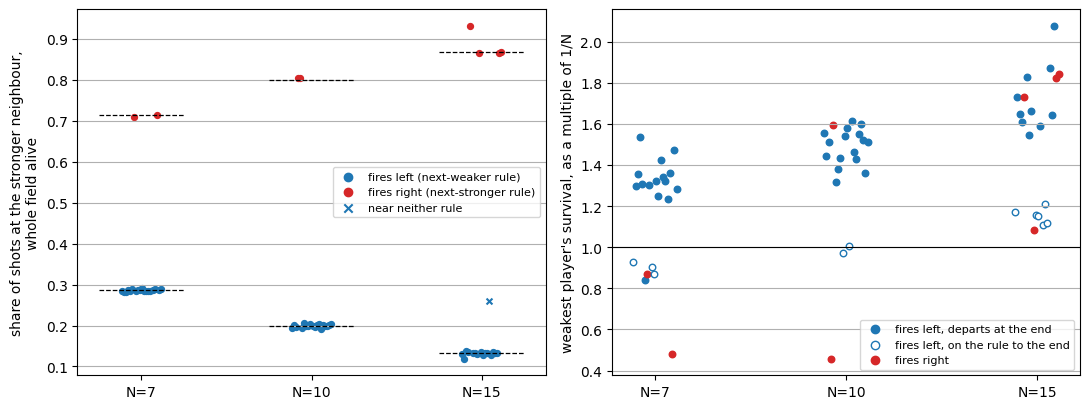

In [13]:
figure, axes = plt.subplots(1, 2, figsize=(11, 4.2))
colours = {"left": "tab:blue", "right": "tab:red"}
for n_index in range(len(PLAYER_COUNTS)):
    n = PLAYER_COUNTS[n_index]
    for seed in SEEDS:
        direction = DIRECTION[(n, seed)]
        jitter = (seed - (len(SEEDS) - 1) / 2) * 0.012
        axes[0].scatter(n_index + jitter, SHARE[(n, seed)], color=colours[direction], s=18,
                        marker="x" if MIXED[(n, seed)] else "o")
        if direction == "left" and ENDGAME[(n, seed)] == "on the rule":
            face = "white"
        else:
            face = colours[direction]
        axes[1].scatter(n_index + jitter, weakest_advantage(R[(n, seed)]), edgecolors=colours[direction],
                        facecolors=face, s=22)
    axes[0].hlines([2.0 / n, (n - 2.0) / n], n_index - 0.25, n_index + 0.25, colors="black",
                   linestyles="dashed", linewidth=0.9)
for axis in axes:
    axis.set_xticks(range(len(PLAYER_COUNTS)))
    axis.set_xticklabels(["N=%d" % n for n in PLAYER_COUNTS])
    axis.grid(True, axis="y")
axes[0].set_ylabel("share of shots at the stronger neighbour,\nwhole field alive")
axes[1].axhline(1.0, color="black", linewidth=0.8)
axes[1].set_ylabel("weakest player's survival, as a multiple of 1/N")
axes[0].scatter([], [], color=colours["left"], label="fires left (next-weaker rule)")
axes[0].scatter([], [], color=colours["right"], label="fires right (next-stronger rule)")
axes[0].scatter([], [], color=colours["left"], marker="x", label="near neither rule")
axes[0].legend(loc="center right", fontsize=8)
axes[1].scatter([], [], edgecolors=colours["left"], facecolors=colours["left"],
                label="fires left, departs at the end")
axes[1].scatter([], [], edgecolors=colours["left"], facecolors="white",
                label="fires left, on the rule to the end")
axes[1].scatter([], [], edgecolors=colours["right"], facecolors=colours["right"],
                label="fires right")
axes[1].legend(loc="lower right", fontsize=8)
figure.tight_layout()
plt.show()

## What this step establishes, derived from the measurements

In [14]:
print("reproduces step 8:", reproduces)
for n in PLAYER_COUNTS:
    lower, upper = exact_interval(RIGHT_COUNT[n], len(SEEDS))
    print("  N=%-3d right-shooting in %d of %d runs (95%% interval %.2f to %.2f)"
          % (n, RIGHT_COUNT[n], len(SEEDS), lower, upper))
print("  dependence on N: permutation p = %.4f" % p_value)
print()
for n in PLAYER_COUNTS:
    for key, label in [("weakest", "weakest player's advantage"), ("exploit", "exploitability")]:
        result = EFFECT[(n, key)]
        if result is None:
            print("  N=%-3d %-28s too few runs in a group" % (n, label))
        else:
            print("  N=%-3d %-28s right minus left %+.4f (s.e. %.4f): %s" % ((n, label) + result))

reproduces step 8: True
  N=7   right-shooting in 2 of 20 runs (95% interval 0.01 to 0.32)
  N=10  right-shooting in 2 of 20 runs (95% interval 0.01 to 0.32)
  N=15  right-shooting in 4 of 20 runs (95% interval 0.06 to 0.44)
  dependence on N: permutation p = 0.7071

  N=7   weakest player's advantage   too few runs in a group
  N=7   exploitability               too few runs in a group
  N=10  weakest player's advantage   too few runs in a group
  N=10  exploitability               too few runs in a group
  N=15  weakest player's advantage   right minus left +0.1116 (s.e. 0.1964): no measurable difference
  N=15  exploitability               right minus left +0.0024 (s.e. 0.0021): no measurable difference


## Reproducibility

A shortened job run twice through the script's own code must give identical results.

In [15]:
def shortened_job():
    saved = (script.UPDATES, script.EVALUATION_EPISODES, script.BASELINE_EPISODES,
             script.SWITCH_EPISODES)
    script.UPDATES = 5
    script.EVALUATION_EPISODES = 200
    script.BASELINE_EPISODES = 200
    script.SWITCH_EPISODES = 100
    try:
        model = script.train_one(7, ARM, 0)
        game = GruelEnv(n=7, reward=script.REWARD, seating=script.SEATING, seed=5000)
        torch.manual_seed(7000)
        summary = script.summarise(script.play_episodes(game, script.make_agent_policy(model), 200), 7)
        summary["switch_test"] = script.switch_test(7, model, 0)
    finally:
        (script.UPDATES, script.EVALUATION_EPISODES, script.BASELINE_EPISODES,
         script.SWITCH_EPISODES) = saved
    return json.dumps(summary, sort_keys=True)


first = shortened_job()
second = shortened_job()
print("identical:", first == second)

identical: True
